# TCGA: agreement, subtypes and threshold diagnostics



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tcga")
from itertools import combinations
import glioma_analysis as ga


## Agreement and sensitivity


In [2]:
models = ("PRISM", "GRASP", "AVICI", "PC", "GES", "GOLEM")
bundle = ga.load_glioma_results(ROOT, models)
graphs = ga.build_model_graphs(bundle, models, min_rate=0.8, edge_mode="directed")
models = tuple(graphs)
agreements = []
cohort = []
counts = []
for dataset in bundle.datasets:
    sets = {m: set(zip(graphs[m][dataset].source, graphs[m][dataset].target)) for m in models}
    for a, b in combinations(models, 2):
        union = sets[a] | sets[b]
        agreements.append(
            dict(
                dataset=dataset,
                model_a=a,
                model_b=b,
                common_edges=len(sets[a] & sets[b]),
                union_edges=len(union),
                jaccard=len(sets[a] & sets[b]) / len(union) if union else np.nan,
            )
        )
    for m, edges in sets.items():
        for kind in ("mut->mut", "mut->rna", "rna->rna", "rna->mut"):
            a, b = kind.split("->")
            count = sum(ga.variable_kind(s) == a and ga.variable_kind(t) == b for s, t in edges)
            counts.append(dict(dataset=dataset, model=m, edge_kind=kind, n_edges=count))
        if "__" in dataset:
            base = dataset.split("__")[0]
            ref = set(zip(graphs[m][base].source, graphs[m][base].target))
            union = ref | edges
            cohort.append(
                dict(
                    dataset=dataset,
                    model=m,
                    cohort_edges=len(ref),
                    subtype_edges=len(edges),
                    common_edges=len(ref & edges),
                    jaccard=len(ref & edges) / len(union) if union else np.nan,
                )
            )
reproducibility = pd.DataFrame(cohort)
display(reproducibility.head(20))


,dataset,model,cohort_edges,subtype_edges,common_edges,jaccard
0,tcga_mut35__astro,PRISM,14,18,0,0.000000
1,tcga_mut35__astro,GRaSP,3,0,0,0.000000
2,tcga_mut35__astro,AVICI,0,0,0,NaN
3,tcga_mut35__astro,PC,0,0,0,NaN
4,tcga_mut35__astro,GES,0,0,0,NaN
5,tcga_mut35__astro,GOLEM,0,0,0,NaN
6,tcga_mut35__gbm,PRISM,14,8,1,0.047619
7,tcga_mut35__gbm,GRaSP,3,0,0,0.000000
8,tcga_mut35__gbm,AVICI,0,0,0,NaN
9,tcga_mut35__gbm,PC,0,20,0,0.000000


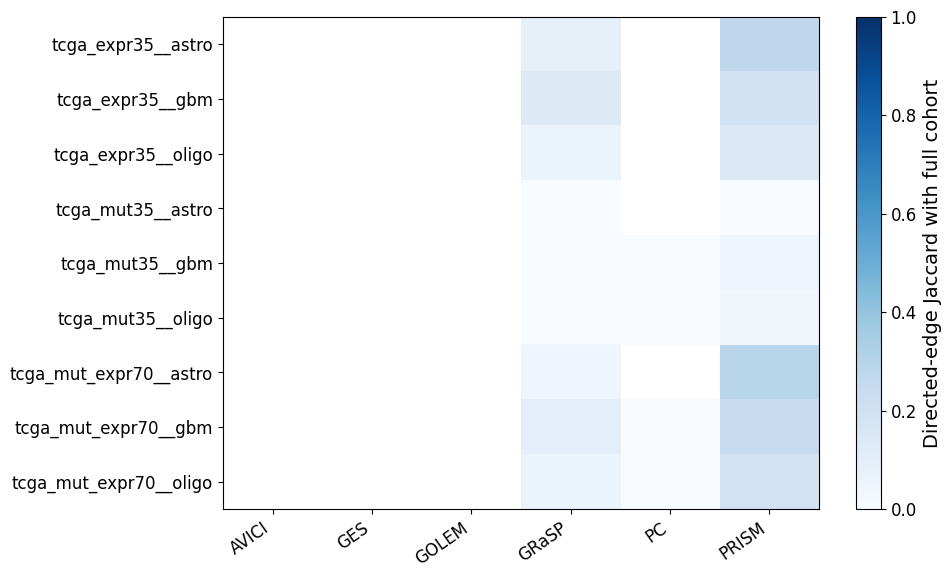

,internal_threshold,n_datasets_available,n_consensus_edges,n_reference_applicable,n_reference_recovered_direct,pct_reference_recovered_direct
0,0.100,12,836,36,7,19.444444
1,0.125,12,644,36,6,16.666667
2,0.150,12,505,36,5,13.888889
3,0.200,12,340,36,4,11.111111


,internal_threshold,dataset,phase,level,group,source,target,effect,line,status,model_path_length,wrong,chance_direta,chance_caminho,evidence,citation,note
0,0.1,tcga_expr35,1,mRNA,transcricao,NOTCH1_expr_log2tpm,EGFR_expr_log2tpm,up-regulates,dashed,nao_encontrada,NaN,False,0.114286,0.136975,Silenciamento de NOTCH1 reduz RNA de EGFR em m...,"Purow et al. 2008, Notch-1 regulates transcrip...",Intervenção sobre NOTCH1 sustenta mecanismo qu...
1,0.1,tcga_expr35,1,mRNA,transcricao,NOTCH1_expr_log2tpm,TP53_expr_log2tpm,up-regulates,,nao_encontrada,NaN,False,0.114286,0.136975,Silenciamento de NOTCH1 reduz RNA de TP53 em l...,"Purow et al. 2008, Notch-1 regulates transcrip...",Evidência experimental em glioma. RNA de NOTCH...
2,0.1,tcga_mut_expr70,1,mRNA,cis,ATRX_mut,ATRX_expr_log2tpm,down-regulates,,direta_sentido_certo,1.0,False,0.013878,0.175510,Alterações truncantes/deleções associadas a me...,"Xie et al. 2019, Omics-based integrated analys...","Associação observacional, não efeito causal is..."
3,0.1,tcga_mut_expr70,1,mRNA,cis,NF1_mut,NF1_expr_log2tpm,down-regulates,,direta_sentido_certo,1.0,False,0.013878,0.175510,Menor RNA médio de NF1 em glioblastomas com al...,NF1 expression profiling in IDH-wildtype gliob...,Associação observacional em GBM IDH-wildtype. ...
4,0.1,tcga_mut_expr70,1,mRNA,cis,FUBP1_mut,FUBP1_expr_log2tpm,down-regulates,,direta_sentido_certo,1.0,False,0.013878,0.175510,Oligodendrogliomas com codeleção 1p/19q e muta...,"Gladitz, Klink and Seifert 2018, Network-based...",Associação observacional no TCGA; não validaçã...
5,0.1,tcga_mut_expr70,1,mRNA,cis,CIC_mut,CIC_expr_log2tpm,down-regulates,,indireta_sentido_certo,3.0,False,0.013878,0.175510,Oligodendrogliomas com codeleção 1p/19q e muta...,"Gladitz, Klink and Seifert 2018, Network-based...",Associação observacional de efeito modesto no ...
6,0.1,tcga_mut_expr70,1,mRNA,cis,EGFR_mut,EGFR_expr_log2tpm,up-regulates,,indireta_sentido_certo,2.0,False,0.013878,0.175510,Casos com mutação de EGFR apresentam RNA de EG...,"Shirai et al. 2024, The development of a custo...",Associação observacional; amplificação e subti...
7,0.1,tcga_mut_expr70,1,mRNA,mut_expr,IDH1_mut,PDGFRA_expr_log2tpm,up-regulates,dashed,indireta_sentido_certo,2.0,False,0.010084,0.171429,Gliomas IDH-mutantes apresentam desregulação d...,"Flavahan et al. 2016, Insulator dysfunction an...","Mecanismo mediado por epigenética, CTCF e enha..."
8,0.1,tcga_mut_expr70,1,mRNA,transcricao,NOTCH1_expr_log2tpm,EGFR_expr_log2tpm,up-regulates,dashed,nao_encontrada,NaN,False,0.164706,0.222689,Silenciamento de NOTCH1 reduz RNA de EGFR em m...,"Purow et al. 2008, Notch-1 regulates transcrip...",Intervenção sobre NOTCH1 sustenta mecanismo qu...
9,0.1,tcga_mut_expr70,1,mRNA,transcricao,NOTCH1_expr_log2tpm,TP53_expr_log2tpm,up-regulates,,indireta_sentido_certo,3.0,False,0.164706,0.222689,Silenciamento de NOTCH1 reduz RNA de TP53 em l...,"Purow et al. 2008, Notch-1 regulates transcrip...",Evidência experimental em glioma. RNA de NOTCH...


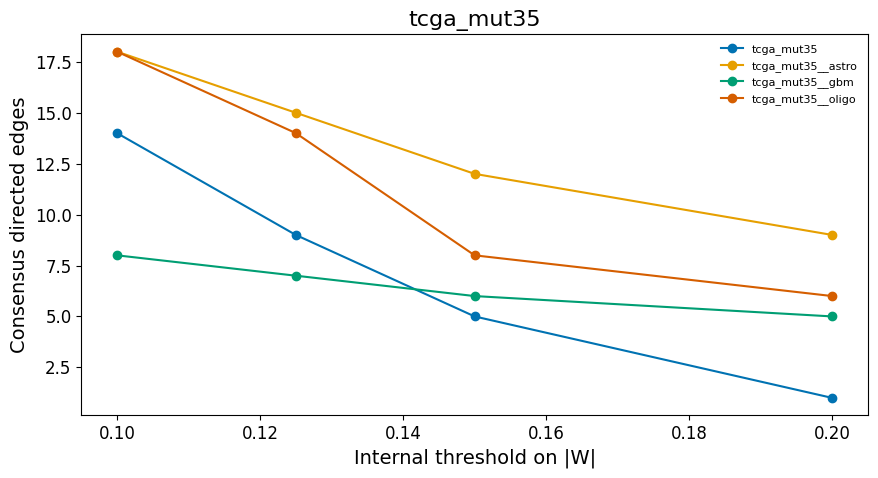

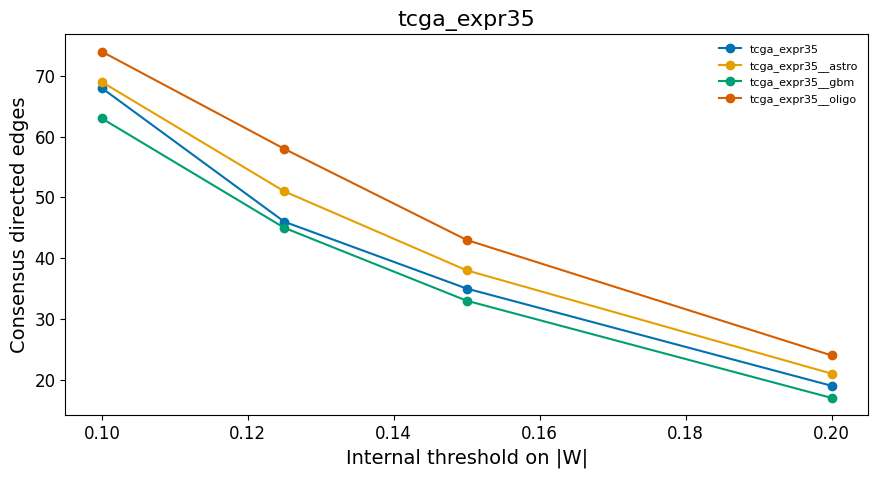

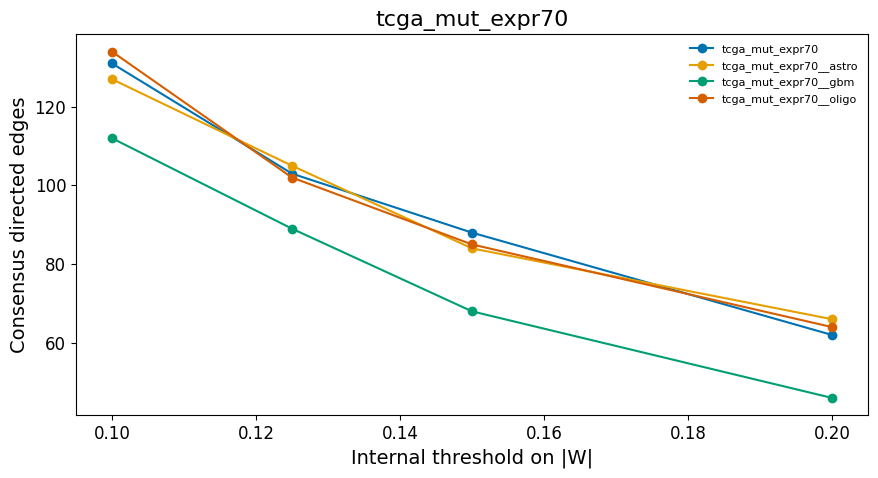

In [3]:
pivot = reproducibility.pivot(index="dataset", columns="model", values="jaccard")
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(pivot.to_numpy(), vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=35, ha="right")
ax.set_yticks(range(len(pivot.index)), pivot.index)
fig.colorbar(im, ax=ax, label="Directed-edge Jaccard with full cohort")
fig.tight_layout()
fig.savefig(th.OUTPUT / "tcga_cohort_subtype_agreement.pdf")
display(fig)
plt.close(fig)
threshold_graphs, _ = ga.build_internal_threshold_graphs(
    bundle,
    thresholds=(0.1, 0.125, 0.15, 0.2),
    consensus_rate=0.8,
    model="PRISM",
    matrix_roots=(
        ROOT / "results/tcga/arms_results",
        ROOT / "results/tcga/arms_results_subtypes",
    ),
)
summary, detail = ga.internal_threshold_sensitivity_summary(bundle, threshold_graphs, phase=1)
display(summary.head(20))
display(detail.head(20))
for base in ga.BASE_DATASETS:
    fig, ax = plt.subplots(figsize=(9, 5))
    for dataset in [base, *[base + "__" + s for s in ga.SUBTYPES]]:
        xs = []
        ys = []
        for threshold, context in threshold_graphs.items():
            xs.append(threshold)
            ys.append(len(context[dataset]))
        ax.plot(xs, ys, marker="o", label=dataset)
    ax.set(xlabel="Internal threshold on |W|", ylabel="Consensus directed edges", title=base)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(th.OUTPUT / f"tcga_threshold_{base}.pdf")
    display(fig)
    plt.close(fig)
